## IAPUCP - Modelos IA
### Transfer Learning

In [1]:
# Importo librerias
import torch
import torchvision
import torchvision.transforms as transforms
import requests
from io import BytesIO


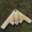

In [2]:
# Abro la imagen con la libreria PIL
from PIL import Image

response = requests.get('https://onetwork.org/dataset/0006.png')
img = Image.open(BytesIO(response.content))
#img = Image.open('images/0006.png')
img

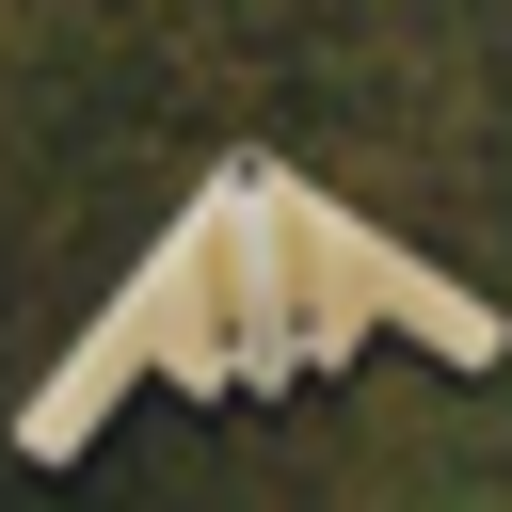

In [3]:
# Se hace un zoom a la imagen
img_zoom = img.resize((512,512))
img_zoom

In [4]:
# Abro una imagen con la libreria matplotlib
# Nuestro el valor de cada pixel en una matriz

# guardo la imagen temporalmente
with open('0006.png', 'wb') as f:
    f.write(response.content)

import matplotlib.pyplot as plt
image = plt.imread('0006.png')

# Muestro el primer pixel de la imagen en una matriz, donde cada pixel es un valor RGB
print(image[0][0])


[0.3254902  0.2901961  0.17254902]


In [5]:
# Muestro el pixel central de la imagen en una matriz, donde cada pixel es un valor RGB
print(image[16][16])

[0.7529412  0.7411765  0.65882355]


### Cada pixel de la imagen a una neurona
![Texto alternativo](https://onetwork.org/dataset/cnn_input.png)

### CIFAR10 Dataset
- 10 clases
- Imagenes de 32 x 32

In [6]:
# Se aplica transformaciones a las imagenes para adaptarlas a VGG16
transform = transforms.Compose([
    transforms.Resize((224, 224)),  # ResNet requiere entradas de 224x224
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],  # Media estándar de ImageNet
        std=[0.229, 0.224, 0.225]    # Desviación estándar de ImageNet
    )
])

batch_size = 4

trainset = torchvision.datasets.CIFAR10(root='./data', train=True,
                                        download=True, transform=transform)
trainloader = torch.utils.data.DataLoader(trainset, batch_size=batch_size,
                                          shuffle=True, num_workers=2)

testset = torchvision.datasets.CIFAR10(root='./data', train=False,
                                       download=True, transform=transform)
testloader = torch.utils.data.DataLoader(testset, batch_size=batch_size,
                                         shuffle=False, num_workers=2)

In [7]:
# Imprimo el tamño del conjunto de entrenamiento y de test
print("El tamaño del conjunto de entrenamiento es: ", len(trainset))
print("El tamaño del conjunto de test es: ", len(testset))

El tamaño del conjunto de entrenamiento es:  50000
El tamaño del conjunto de test es:  10000


In [8]:
# Limitamos el tamaño del dataset para entrenamiento y prueba, para una ejecución más rápida
# Definimos los tamaños deseados 
train_limit = 2000
test_limit = 500

# Creamos subconjuntos tomando los primeros índices de cada dataset
train_indices = range(train_limit)
test_indices = range(test_limit)

trainset_limited = torch.utils.data.Subset(trainset, train_indices)
testset_limited = torch.utils.data.Subset(testset, test_indices)

# Reemplazamos los loaders para que usen los conjuntos limitados
batch_size = 4

trainloader = torch.utils.data.DataLoader(trainset_limited, batch_size=batch_size,
                                          shuffle=True, num_workers=2)

testloader = torch.utils.data.DataLoader(testset_limited, batch_size=batch_size,
                                         shuffle=False, num_workers=2)

# Verificamos los nuevos tamaños
print("Nuevo tamaño de entrenamiento:", len(trainset_limited))
print("Nuevo tamaño de test:", len(testset_limited))

Nuevo tamaño de entrenamiento: 2000
Nuevo tamaño de test: 500


In [9]:
# Obtengo las 10 clases del dataset CIFAR10
classes = ('plane', 'car', 'bird', 'cat',
           'deer', 'dog', 'frog', 'horse', 'ship', 'truck')

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-0.5332649..1.6631372].


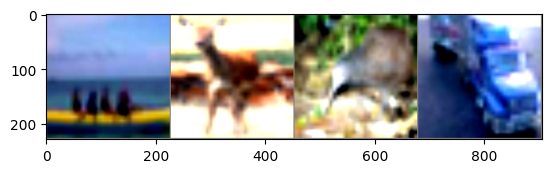

 ship  deer  bird truck


In [10]:
# Se muestra las imagenes de un batch del conjunto de datos
import matplotlib.pyplot as plt
import numpy as np

# Funcion para mostrar una imagen
def imshow(img):
    img = img / 2 + 0.5     # unnormalize
    npimg = img.numpy()
    plt.imshow(np.transpose(npimg, (1, 2, 0)))
    plt.show()

# Obtengo imagenes de un batch
dataiter = iter(trainloader)
images, labels = next(dataiter)

# Muestro imagenes
imshow(torchvision.utils.make_grid(images))
# Se muestra las etiquetas
print(' '.join('%5s' % classes[labels[j]] for j in range(batch_size)))

## Transfer Learning

In [11]:
import torch.nn as nn
import torchvision.models as models

# Cargamos el modelo ResNet18 preentrenado
net = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)

# Modificamos la capa de salida final (fc) para que coincida con las 10 clases de CIFAR-10
net.fc = nn.Linear(net.fc.in_features, 10)

print(net)

ResNet(
  (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (layer1): Sequential(
    (0): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    )
    (1): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
  

In [12]:
import torch.optim as optim

# Se entrena la red en la tarjeta gráfica si está disponible
device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
print(device)

net.to(device)

# Función de pérdida y optimizador
criterion = nn.CrossEntropyLoss()
# Si congelaste las capas internas, puedes pasar solo los parámetros entrenables:
# optimizer = optim.SGD(filter(lambda p: p.requires_grad, net.parameters()), lr=0.001, momentum=0.9)
#optimizer = optim.SGD(net.parameters(), lr=0.001, momentum=0.9)

cuda:0


In [13]:
# Separar los parámetros de la base y del clasificador final (fc en ResNet)
# lr = 0.001 para la capa final y lr = 0.0001 para las capas convolucionales

optimizer = optim.SGD([
    {'params': [p for name, p in net.named_parameters() if 'fc' not in name], 'lr': 1e-4}, # Base convolucional (lento)
    {'params': net.fc.parameters(), 'lr': 1e-3}                                            # Capa lineal final (rápido)
], momentum=0.9)

In [14]:
# Se entrena la red en la tarjeta grafica
device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
print(device)

net.to(device)

cuda:0


ResNet(
  (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (layer1): Sequential(
    (0): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    )
    (1): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
  

In [15]:
epochs = 2  # VGG16 es más pesado, con pocas épocas se pueden ver buenos resultados
losses = []
accuracies = []

for epoch in range(epochs):
    running_loss = 0.0
    correct_train = 0
    total_train = 0
    
    net.train() # Aseguramos que el modelo esté en modo entrenamiento
    for i, data in enumerate(trainloader, 0):
        inputs, labels = data[0].to(device), data[1].to(device)

        optimizer.zero_grad()

        outputs = net(inputs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        # Acumular la pérdida
        running_loss += loss.item()
        
        # Calcular aciertos para el accuracy de entrenamiento
        _, predicted = torch.max(outputs.data, 1)
        total_train += labels.size(0)
        correct_train += (predicted == labels).sum().item()

    # Métricas al finalizar la época
    epoch_loss = running_loss / len(trainloader)
    epoch_accuracy = 100 * correct_train / total_train
    
    losses.append(epoch_loss)
    accuracies.append(epoch_accuracy)
    
    print(f'Epoch [{epoch + 1}/{epochs}] ---> Loss: {epoch_loss:.3f} | Accuracy (Train): {epoch_accuracy:.2f}%')

print('Finished Training')

Epoch [1/2] ---> Loss: 1.544 | Accuracy (Train): 46.45%
Epoch [2/2] ---> Loss: 0.949 | Accuracy (Train): 67.10%
Finished Training


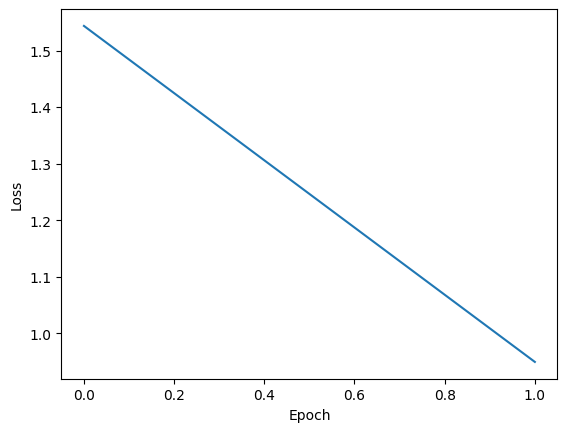

In [16]:
# Grafico el loss del entrenamiento
import matplotlib.pyplot as plt
plt.plot(losses)
plt.ylabel('Loss')
plt.xlabel('Epoch')
plt.show()

In [17]:
# Se guarda el estado del modelo entrenado
PATH = 'cifar_net_resnet.pth'
torch.save(net.state_dict(), PATH)
print("¡Modelo guardado exitosamente!")

¡Modelo guardado exitosamente!


In [18]:
# Verifico en el conjunto de datos de prueba la metrica de accuracy
correct = 0
total = 0
with torch.no_grad():
    for data in testloader:
        images, labels = data[0].to(device), data[1].to(device)
        outputs = net(images)
        _, predicted = torch.max(outputs.data, 1)
        total += labels.size(0)
        correct += (predicted == labels).sum().item()

print('Accuracy of the network on test images: %d %%' % ( 100 * correct / total))

Accuracy of the network on test images: 63 %


Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-0.558952..1.7938564].


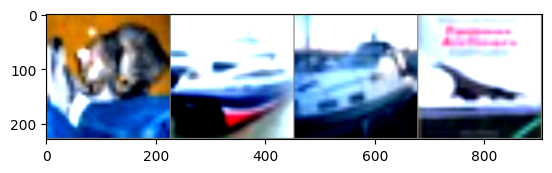

GroundTruth:    cat  ship  ship plane
Predicted:    cat   car truck plane


In [19]:
# Obtener un batch de imágenes
dataiter = iter(testloader)
images, labels = next(dataiter)

# Mover los datos a la GPU si el modelo está en la GPU
images, labels = images.to(device), labels.to(device)

# Mostrar imágenes
imshow(torchvision.utils.make_grid(images.cpu()))  # Mover imágenes de vuelta a la CPU para mostrarlas
print('GroundTruth: ', ' '.join('%5s' % classes[labels[j]] for j in range(len(labels))))

# Obtener las predicciones del modelo
outputs = net(images)
_, predicted = torch.max(outputs, 1)

print('Predicted: ', ' '.join('%5s' % classes[predicted[j]] for j in range(len(predicted))))